In [1]:
import sys
import os
import importlib.util
project_dir = r"C:\Users\douga\Documents\Y4 Project"
sys.path.insert(0, project_dir)
sys.modules.pop("scripts", None)
import numpy as np
import pickle
import json
import corner
import jax
import matplotlib.pyplot as plt
import ultranest
import tinygp
import ipywidgets

from scripts import pitchfork_compile, pitchfork_sampler, posterior_plot

In [2]:
pitchfork_dir = os.path.join(project_dir, "pitchfork")

with open(os.path.join(pitchfork_dir, "pitchfork.json"), "r") as fp:
    pitchfork_dict = json.load(fp)

with open(os.path.join(pitchfork_dir, "pitchfork_info.json"), "r") as fp:
    pitchfork_info = json.load(fp)

pitchfork_cov = np.loadtxt(
    os.path.join(pitchfork_dir, "pitchfork_covariance.txt")
)

pitchfork = pitchfork_compile(pitchfork_dict, pitchfork_info)



In [3]:
sampler = pitchfork_sampler(pitchfork, pitchfork_cov)
priors = sampler.priors

labels = ['initial_mass', 'initial_Zinit', 'initial_Yinit', 'initial_MLT', 'star_age', 'a', 'b']

size = 10000
prior_samples = np.array([prior.rvs(size=size) for prior in priors])

In [6]:
project_dir = r"C:\Users\douga\Documents\Y4 Project"
os.chdir(project_dir)

star_name = '16CygB'
results = sampler(star_name, save_as='16CygB_results.pkl')

[pitchfork_sampler] sampling posterior of 16CygB!
[pitchfork_sampler] GP params: gp_var=4, gp_ls_factor=7
[pitchfork_sampler] Considering freqs in range: 13 ≤ n ≤ 27
[ultranest] Sampling 400 live points from prior ...


[ultranest] Explored until L=-9  63 [-9.1033..-9.1026]*| it/evals=7409/316743 eff=3.0056% N=400           0 0 0 0 
[ultranest] Likelihood function evaluations: 316743
[ultranest]   logZ = -22.9 +- 0.1375
[ultranest] Effective samples strategy satisfied (ESS = 2501.2, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.05 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.14, need <0.5)
[ultranest]   logZ error budget: single: 0.17 bs:0.14 tail:0.01 total:0.14 required:<0.50
[ultranest] done iterating.
[pitchfork_sampler] finished in 77m 59.8s!


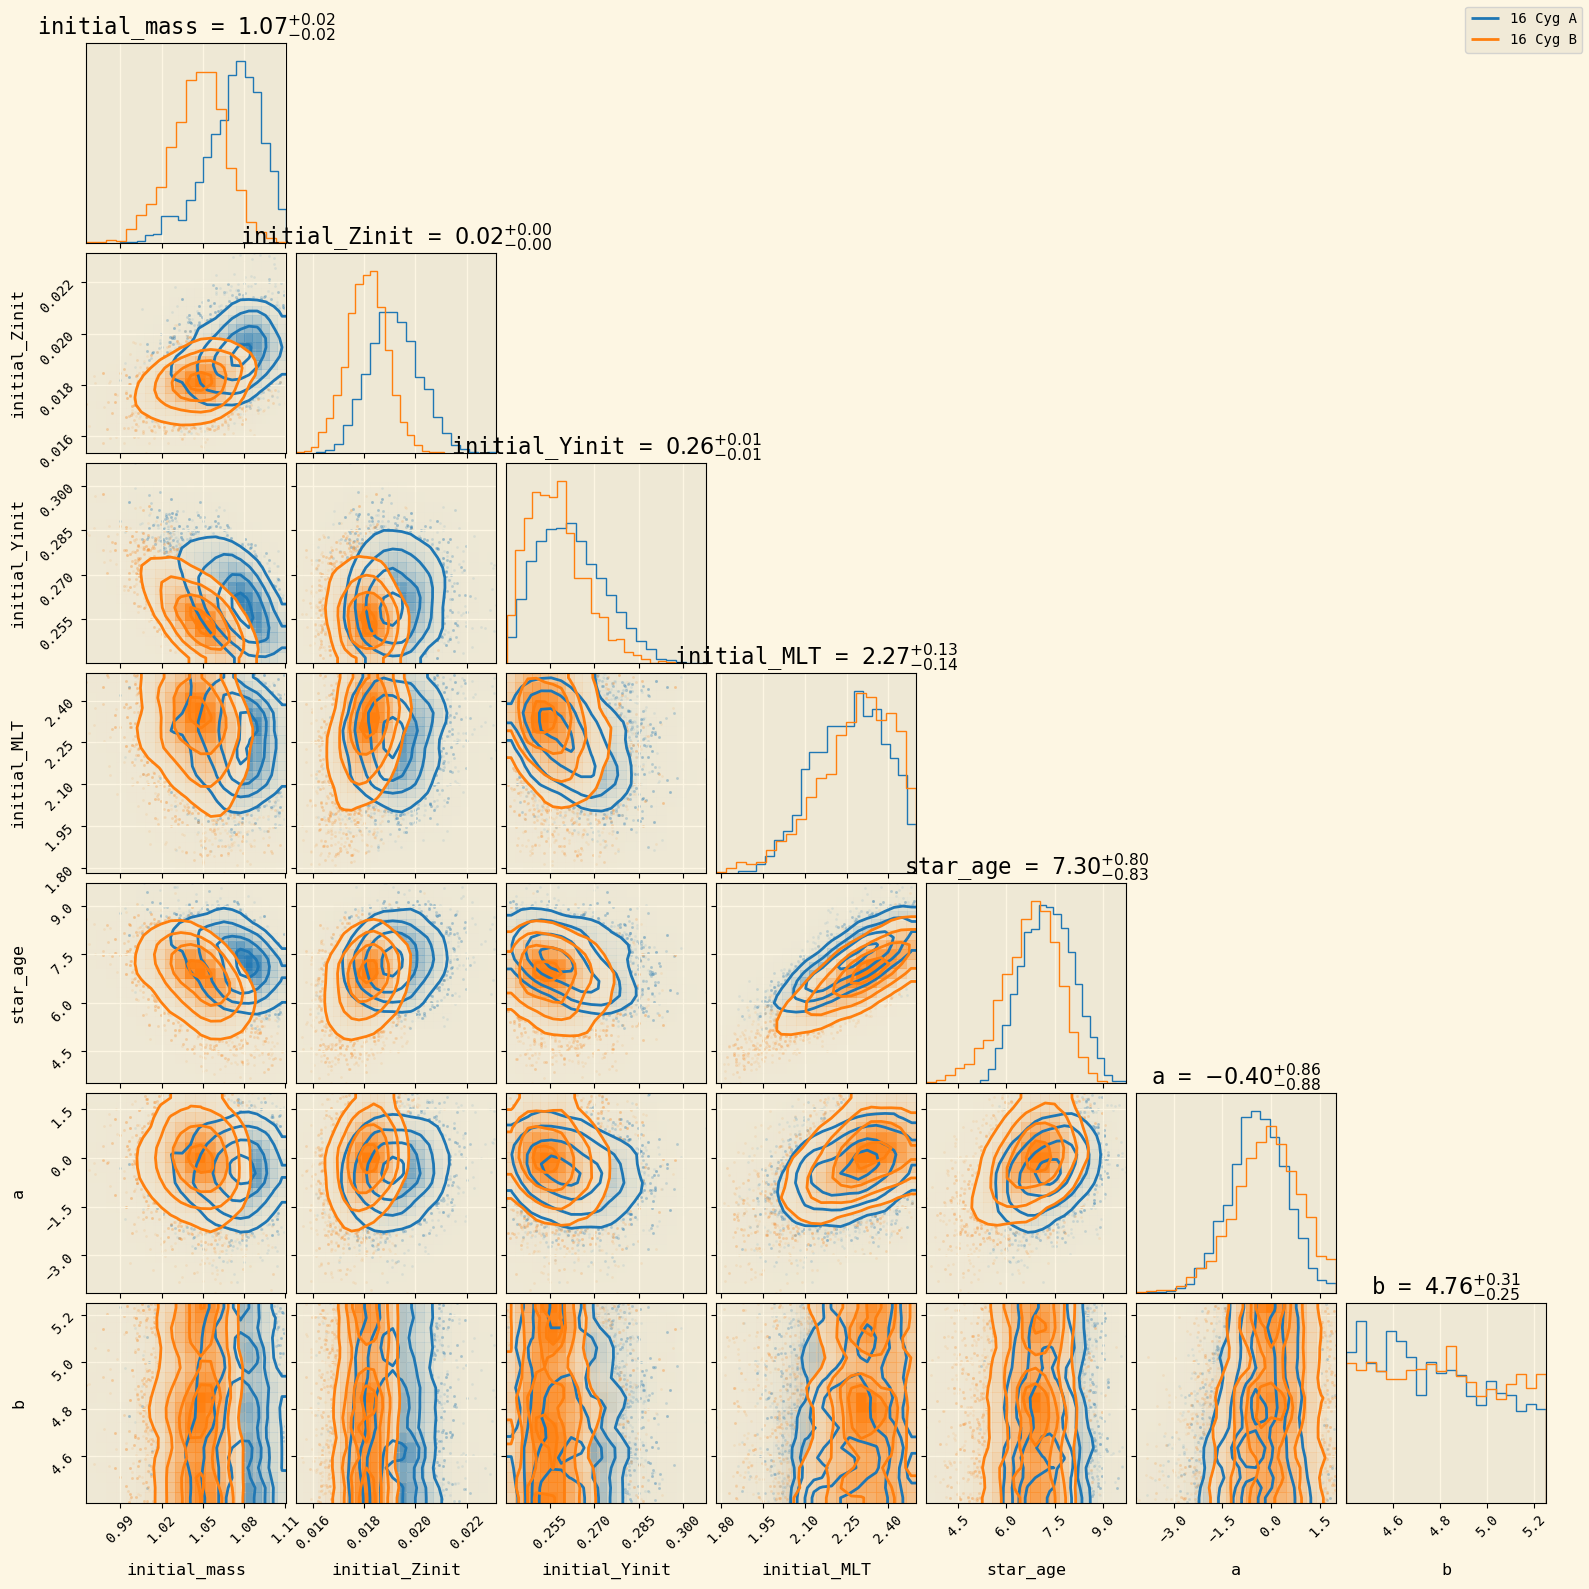

In [13]:
os.chdir(r"C:\Users\douga\Documents\Y4 Project")

with open('stars/16CygA/16CygA_results.pkl', 'rb') as fp:
    results_A = pickle.load(fp)

with open('stars/16CygB/16CygB_results.pkl', 'rb') as fp:
    results_B = pickle.load(fp)

# Extract posterior samples
# Check the structure of results if these keys are not correct
samples_A = results_A["samples"]
samples_B = results_B["samples"]

labels = [
    'initial_mass',
    'initial_Zinit',
    'initial_Yinit',
    'initial_MLT',
    'star_age',
    'a',
    'b'
]

# Plot both posterior distributions on the same figure
fig = corner.corner(
    samples_A,
    labels=labels,
    color="tab:blue",
    smooth=True,
    hist_kwargs={"density": True},
    show_titles=True
)

corner.corner(
    samples_B,
    labels=labels,
    color="tab:orange",
    smooth=True,
    hist_kwargs={"density": True},
    fig=fig,
    show_titles=False
)

# Add legend
handles = [
    plt.Line2D([], [], color="tab:blue", label="16 Cyg A"),
    plt.Line2D([], [], color="tab:orange", label="16 Cyg B")
]
fig.legend(handles=handles, loc="upper right")

plt.show()

In [6]:
star_name = 'Sun_nomodes'

star_dict = {
    'calc_effective_T': [5777, 20],
    'luminosity': [1, 0.001],
    'star_feh': [0, 0.01],
    'nu_0_6': [972.615, 1000],
    'nu_0_7': [1117.993, 1000],
    'nu_0_8': [1263.198, 1000],
    'nu_0_9': [1407.472, 1000],
    'nu_0_10': [1548.336, 1000],
    'nu_0_11': [1686.594, 1000],
    'nu_0_12': [1822.202, 1000],
    'nu_0_13': [1957.452, 1000],
    'nu_0_14': [2093.518, 1000],
    'nu_0_15': [2228.749, 1000],
    'nu_0_16': [2362.788, 1000],
    'nu_0_17': [2496.18, 1000],
    'nu_0_18': [2629.668, 1000],
    'nu_0_19': [2764.142, 1000],
    'nu_0_20': [2899.022, 1000],
    'nu_0_21': [3033.754, 1000],
    'nu_0_22': [3168.618, 1000],
    'nu_0_23': [3303.52, 1000],
    'nu_0_24': [3438.992, 1000],
    'nu_0_25': [3574.893, 1000],
    'nu_0_26': [3710.717, 1000],
    'nu_0_27': [3846.993, 1000],
    'nu_0_28': [3984.214, 1000],
    'dnu': [135.1, 0.2],
    'nu_max': [3141, 12]
}

## save to expected location:

star_dir = os.path.join("stars", star_name)
os.makedirs(star_dir, exist_ok=True)

with open(os.path.join(star_dir, f"{star_name}.json"), "w") as fp:
    json.dump(star_dict, fp, indent=4)

print("Saved to:", os.path.abspath(
    os.path.join(star_dir, f"{star_name}.json")
))

Saved to: C:\Users\douga\Documents\Y4 Project\tutorials\stars\Sun_nomodes\Sun_nomodes.json


In [7]:
sampler = pitchfork_sampler(pitchfork, pitchfork_cov)

results = sampler(
    star_name,
    save_as=f"{star_name}_results.pkl"
)

[pitchfork_sampler] sampling posterior of Sun_nomodes!
[pitchfork_sampler] GP params: gp_var=4, gp_ls_factor=7
[pitchfork_sampler] Considering freqs in range: 6 ≤ n ≤ 28
[ultranest] Sampling 400 live points from prior ...


[ultranest] Explored until L=-2e+02  .87 [-176.9394..-176.9392]*| it/evals=5624/81764 eff=6.9121% N=400    0 
[ultranest] Likelihood function evaluations: 81778
[ultranest]   logZ = -186.4 +- 0.1124
[ultranest] Effective samples strategy satisfied (ESS = 1912.5, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.45+-0.06 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.11, need <0.5)
[ultranest]   logZ error budget: single: 0.14 bs:0.11 tail:0.01 total:0.11 required:<0.50
[ultranest] done iterating.
[pitchfork_sampler] finished in 2m 54.3s!


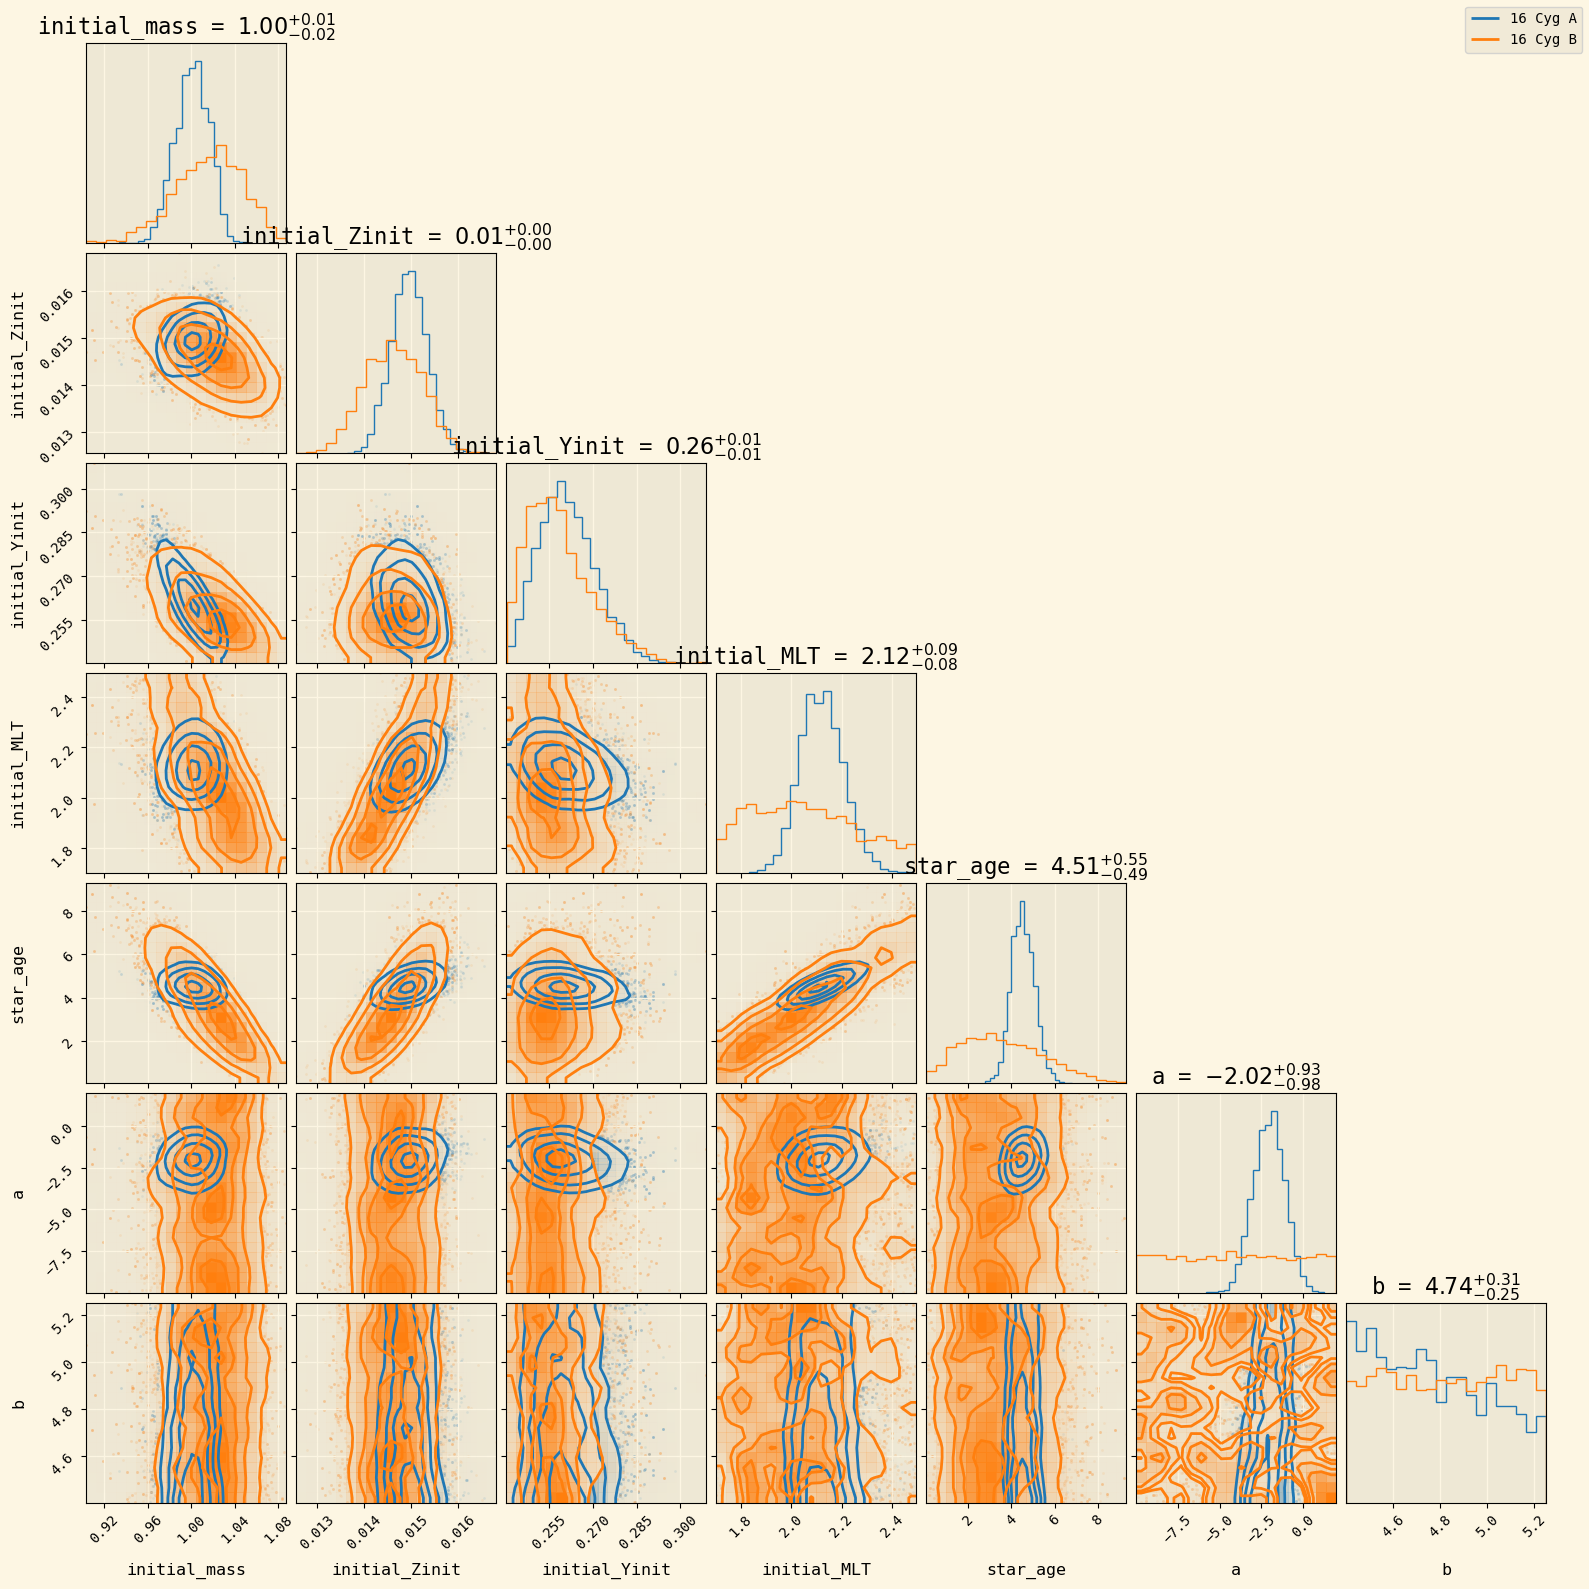

In [13]:
os.chdir(r"C:\Users\douga\Documents\Y4 Project")

with open('stars/Sun/Sun_results.pkl', 'rb') as fp:
    results_A = pickle.load(fp)

with open('stars/Sun_nomodes/Sun_nomodes_results.pkl', 'rb') as fp:
    results_B = pickle.load(fp)

# Extract posterior samples
# Check the structure of results if these keys are not correct
samples_A = results_A["samples"]
samples_B = results_B["samples"]

labels = [
    'initial_mass',
    'initial_Zinit',
    'initial_Yinit',
    'initial_MLT',
    'star_age',
    'a',
    'b'
]

# Plot both posterior distributions on the same figure
fig = corner.corner(
    samples_A,
    labels=labels,
    color="tab:blue",
    smooth=True,
    hist_kwargs={"density": True},
    show_titles=True
)

corner.corner(
    samples_B,
    labels=labels,
    color="tab:orange",
    smooth=True,
    hist_kwargs={"density": True},
    fig=fig,
    show_titles=False
)

# Add legend
handles = [
    plt.Line2D([], [], color="tab:blue", label="16 Cyg A"),
    plt.Line2D([], [], color="tab:orange", label="16 Cyg B")
]
fig.legend(handles=handles, loc="upper right")

plt.show()